# Task for session2_cont and session3: 
## Edge-Preserving Denoising Filters & Feature Matching

**Instructions:**  
**please dont use .py to solve this task, just use tasks2.ipynb and edit the cells.**
- After forking the [SkyXperts-Vision-Course repo](https://github.com/ffathy-tdx/SkyXperts-Vision-Course) on GitHub. (you should have already dont this in the last session & uploaded task1)
- Go to your fork of the repo on GitHub.
- At the top, look for a yellow box that says “This branch is X commits behind…”
- Click the Sync fork or Update branch button.
The new task will show up in your tasks/ folder.  
- Upload your task to your forked repo (like you've done with task1 before)
---

## 1. DoG, LoG, and Edge-Preserving Denoising Filters

**Task:**
- Briefly read the descriptions below, then apply each filter to `'sample.jpg'` (or any test image you choose).
- Compare the results visually and write your observations.

**Background:**
- **DoG (Difference of Gaussian):** Used for edge detection by subtracting two blurred versions of the image (with different Gaussian sigmas).
- **LoG (Laplacian of Gaussian):** Uses a single Gaussian blur followed by Laplacian to highlight regions of rapid intensity change (edges).
- **Edge-Preserving Denoising (Bilateral Filter):** Smooths image while preserving edges (unlike simple Gaussian blur). You've already used this at the end of task1.

---

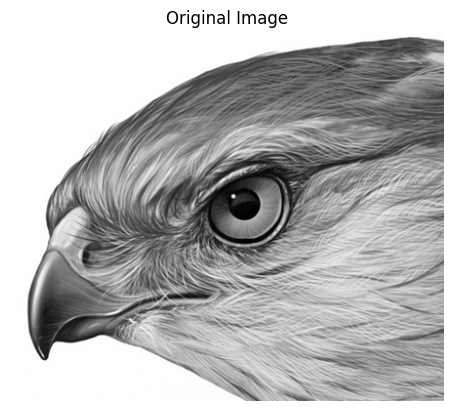

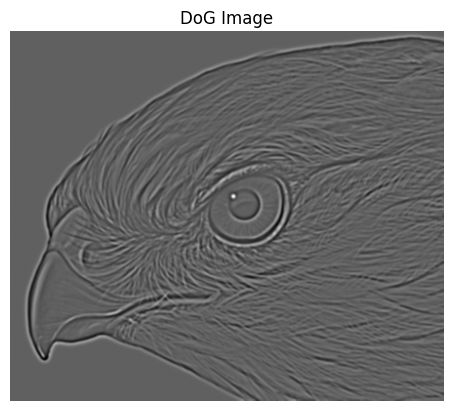

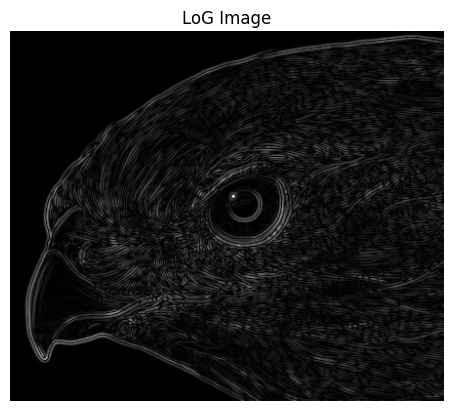

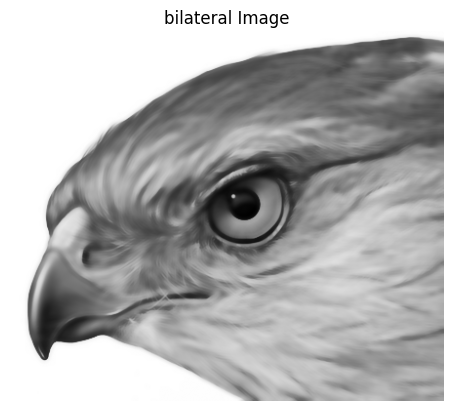

In [9]:
# Import required libraries
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Load image
path= r'C:\Users\habib\OneDrive\Desktop\gettingintoit\skyexperts CV training\Session2\images\hawk.png'
img = cv.imread(path, 0)  # Use grayscale for filtering ->this is the zero, it's what makes it like this
plt.imshow(img, cmap='gray'); plt.axis('off'); plt.title('Original Image'); plt.show()

# TODO: Apply DoG
float_img= img.astype(np.float32)
small_sigma=cv.GaussianBlur(float_img, (0 ,0), 1)
big_sigma=cv.GaussianBlur(float_img, (0,0), 2)
dog=small_sigma - big_sigma
plt.imshow(dog, cmap='gray'); plt.axis('off'); plt.title('DoG Image'); plt.show()


# TODO: Apply LoG
blur= cv.GaussianBlur(img, (5, 5), 1)
log=cv.Laplacian(blur, cv.CV_64F, ksize=3)
log_abs=np.abs(log) #i don't really get what that is but it's somehting like normalization, i will get to it later
plt.imshow(log_abs, cmap='gray'); plt.axis('off'); plt.title('LoG Image'); plt.show()

# TODO: Apply bilateral (edge-preserving) filter
bilat= cv.bilateralFilter(img, 9, 75, 75)
plt.imshow(bilat, cmap='gray'); plt.axis('off'); plt.title('bilateral Image'); plt.show()

# Show all results for comparison

**Q1: What differences do you observe between DoG, LoG, and the edge-preserving filter?**

_Write your observations here._

## 2. Keypoints & Descriptors: SIFT vs. ORB

**Task:**
- Detect and plot keypoints on `'sample.jpg'` using SIFT and ORB.
- Compare the number and distribution of detected keypoints.

**Background:**
- **Keypoints:** Distinctive image points (corners/blobs) useful for matching.
- **Descriptors:** Vectors that describe local patches around keypoints for comparison/matching.

---

SIFT keypoints: 961
ORB keypoints : 500
SIFT descriptor shape: (961, 128)
ORB descriptor shape : (500, 32)


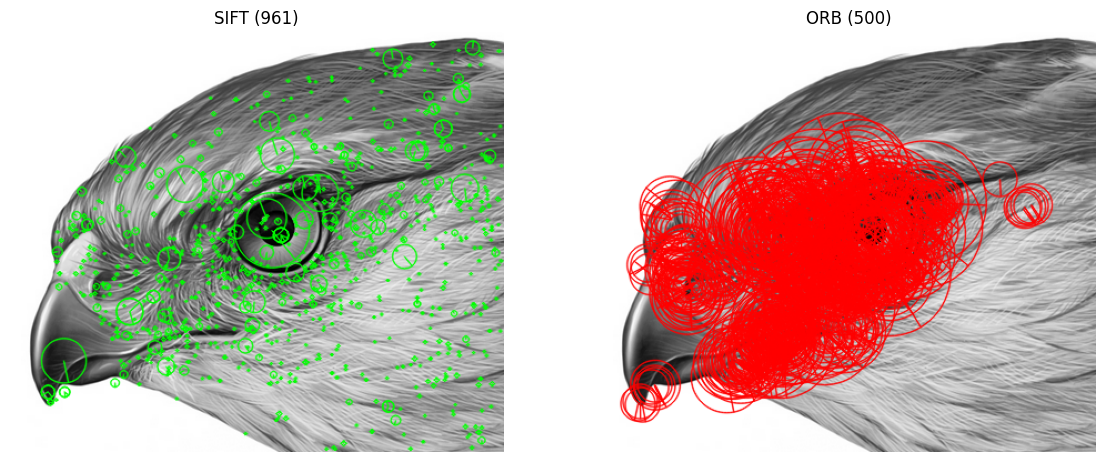

In [ ]:
# Detect and plot SIFT keypoints
sift = cv.SIFT_create()
kp_sift, des_sift = sift.detectAndCompute(img, None)

# Detect and plot ORB keypoints
orb = cv.ORB_create()
kp_orb, des_orb = orb.detectAndCompute(img, None)

img_sift = cv.drawKeypoints(img, kp_sift, None, color=(0, 255, 0), flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
img_orb = cv.drawKeypoints(img, kp_orb, None, color=(255, 0, 0), flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)


# TODO: Count and compare number of keypoints for SIFT and ORB
print('SIFT keypoints:', len(kp_sift))
print('ORB keypoints :', len(kp_orb))
print('SIFT descriptor shape:', des_sift.shape)   # (N, 128) floats
print('ORB descriptor shape :', des_orb.shape)

plt.figure(figsize=(14, 6))
plt.subplot(1, 2, 1); plt.imshow(img_sift); plt.title(f'SIFT ({len(kp_sift)})'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(img_orb);  plt.title(f'ORB ({len(kp_orb)})');  plt.axis('off')
plt.show()
# i was too lazy to write all these print () so i got some help from claude :|


**Q2: How do the number and distribution of keypoints differ between SIFT and ORB?**

sift finds as many as possible keypoints, but orb is limited to the blobs i guess, and the distribution in orb is focused on blobs unlike sift which is all over the object

## 3. Feature Matching with Descriptors

**Task:**
- Load a second image (e.g., `'sample2.jpg'`).
- Detect keypoints/descriptors using SIFT or ORB in both images.
- Match the features between the images using BFMatcher or FLANN.
- Plot the top matches.

**Background:**
- **Feature matching** helps recognize objects/scenes or estimate image transformations.

---

In [ ]:
# Load second image
img2 = cv.imread(img, 0)

# Detect SIFT keypoints/descriptors in both images

# BFMatcher with default params
bf = cv2.BFMatcher()

# Draw matches

# bonus TODO: Try with ORB or FLANN if you like

**Q3: What do you notice about the feature matches? Are there any mismatches or errors? How might you improve the matching process?**

_Write your answer here._

**Bonus Task (Optional, for extra credit):**
- Try using different image preprocessing steps *before* edge detection or feature extraction.
    - For example:
        - Add noise to your image (e.g., Gaussian noise, salt-and-pepper noise).
        - Apply a sharpening filter to your image.
    - Then, run DoG, LoG, or any edge-preserving filter and observe the changes.
- **What to do:**
    - Show the results (images/plots) for at least one type of preprocessing + edge detection.
    - Briefly explain:
        - How does noise affect edge maps or keypoints?
        - Does sharpening make features easier or harder to detect/match?

**You can add your code and observations in the cells below.**


In [ ]:
# Write your code here

_What are your observations?_
write them here

## 4. Reflection (Optional)

- What was the most challenging or interesting part of this task for you?
- Any feedback or thoughts?

_Write your reflection here._